# Session fragments

Hypothesis to test, not to assume: some sessions are consecutive pieces of the same browsing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hrflow_recsys.data import load_data
from hrflow_recsys.evaluate import evaluate_recommender, recommend_all
from hrflow_recsys.fragments import (
    build_chains,
    first_items,
    next_first,
    next_gap,
    with_next_first,
)
from hrflow_recsys.metrics import action_accuracy, final_score, mrr_at_k
from hrflow_recsys.models.baselines import last_action
from hrflow_recsys.models.hybrid import Hybrid
from hrflow_recsys.models.markov import Markov
from hrflow_recsys.split import grouped_split, train_val_split

x_train, y_train, x_test, jobs = load_data()
train = x_train.merge(y_train, on="session_id")
first = first_items(x_train)

## 1. Is the target the first job of another session?

In [2]:
start_counts = pd.concat([x_train, x_test])["job_ids"].str[0].value_counts()
own_start = (train["job_ids"].str[0] == train["job_id"]).to_numpy()
other_starts = start_counts.reindex(train["job_id"]).fillna(0).to_numpy() - own_start
round(float((other_starts > 0).mean()), 3)

0.891

Offsets -1 and +2 are controls: if fragments were a coincidence, +1 would not stand out.

In [3]:
rates = {}
for offset in [-1, 1, 2]:
    shifted = first.reindex(train["session_id"] + offset)
    rates[f"s{offset:+d}"] = (shifted["job_id"].to_numpy() == train["job_id"].to_numpy()).mean()
pd.Series(rates).round(4)

s-1    0.0003
s+1    0.6054
s+2    0.0001
dtype: float64

In [4]:
following = first.reindex(train["session_id"] + 1)
is_next = following["job_id"].to_numpy() == train["job_id"].to_numpy()
same_action = following["action"].to_numpy() == train["action"].to_numpy()
round(float(same_action[is_next].mean()), 4), int(is_next.sum())

(0.9999, 9615)

The hypothesis holds: 60.5 % of targets are the first job of session s+1 (against 0.03 % for s-1 and 0.01 % for s+2), and in those 9,615 cases the action matches 99.99 % of the time; the remaining matches with any other session (89.1 % in total) are coincidences on popular first jobs.

## 2. Chains of sessions

In [5]:
chains = build_chains(x_train, y_train)
chain_len = chains.value_counts()
(
    len(chain_len),
    chain_len.describe().round(1).to_dict(),
    round(float((chain_len.reindex(chains).to_numpy() > 1).mean()), 3),
)

(6267,
 {'count': 6267.0,
  'mean': 2.5,
  'std': 2.3,
  'min': 1.0,
  '25%': 1.0,
  '50%': 2.0,
  '75%': 3.0,
  'max': 14.0},
 0.815)

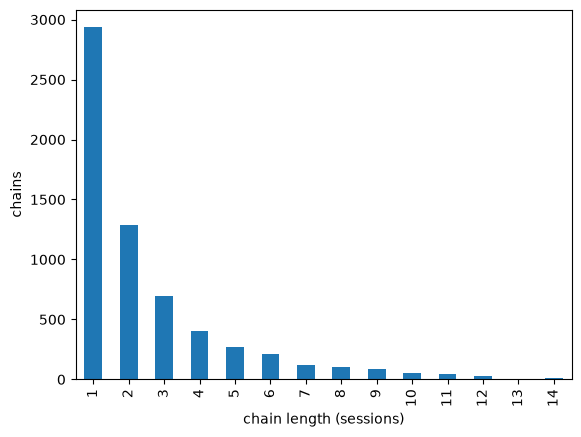

In [6]:
chain_len.value_counts().sort_index().plot.bar()
plt.xlabel("chain length (sessions)")
plt.ylabel("chains");

The 15,882 train sessions form 6,267 chains (median 2 sessions, max 14), and 81.5 % of sessions belong to a chain of at least 2.

## 3. Random split vs split grouped by chain

In [7]:
def val_mrr(split):
    x_fit, x_val, y_fit, y_val = split
    return {
        "Markov": evaluate_recommender(Markov().fit(x_fit, y_fit), x_val, y_val),
        "Hybrid": evaluate_recommender(Hybrid().fit(x_fit, y_fit, jobs), x_val, y_val),
    }


pd.DataFrame(
    {
        "random": val_mrr(train_val_split(x_train, y_train)),
        "grouped by chain": val_mrr(grouped_split(x_train, y_train, chains)),
    }
).round(4)

,random,grouped by chain
Markov,0.089,0.0794
Hybrid,0.099,0.0899


Grouping by chain lowers MRR@10 from 0.0890 to 0.0794 for Markov and from 0.0990 to 0.0899 for Hybrid: the random split overestimates by about 0.01 because neighbouring fragments of the same browsing end up in train.

## 4. Exploiting the leak

For a val session s, when s+1 is in x (train and val, no y), its first job goes to rank 1 and its first action is the predicted action. Otherwise Hybrid + last_action. Random split.

In [8]:
x_fit, x_val, y_fit, y_val = train_val_split(x_train, y_train)
val = x_val.merge(y_val, on="session_id")
recs = recommend_all(Hybrid().fit(x_fit, y_fit, jobs), val["job_ids"].tolist())
actions = [last_action(a) for a in val["actions"]]
following = next_first(x_train).reindex(val["session_id"])
has_next = following["job_id"].notna().to_numpy()
round(float(has_next.mean()), 4)

1.0

In [9]:
leak_recs = with_next_first(recs, val, x_train)
leak_actions = np.where(has_next, following["action"], actions)
variants = {
    "without": (recs, actions),
    "leak job + leak action": (leak_recs, leak_actions),
    "leak job + last_action": (leak_recs, actions),
}
scores = {}
for name, (r, a) in variants.items():
    mrr = mrr_at_k(r, val["job_id"].tolist())
    acc = action_accuracy(a, val["action"].tolist())
    scores[name] = {"MRR@10": mrr, "accuracy": acc, "final": final_score(mrr, acc)}
pd.DataFrame(scores).T.round(4)

,MRR@10,accuracy,final
without,0.0990,0.8501,0.3243
leak job + leak action,0.6236,0.8312,0.6859
leak job + last_action,0.6236,0.8501,0.6916


Putting the first job of s+1 at rank 1 raises MRR@10 from 0.0990 to 0.6236; keeping last_action for the action gives the best final score, 0.6916 against 0.6859 with the action of s+1 and 0.3243 without the leak.

## 5. Does the test behave like the train?

Links cannot be checked without y_test. Proxy: share of sessions s where |first job of s+1 - last job of s| <= 100, with the train split by true link as reference.

In [10]:
train_close = next_gap(x_train) <= 100
test_close = next_gap(x_test) <= 100
linked = pd.Series(is_next, index=train["session_id"]).reindex(train_close.index)
rates = pd.Series(
    {
        "train": train_close.mean(),
        "test": test_close.mean(),
        "train, linked": train_close[linked].mean(),
        "train, not linked": train_close[~linked].mean(),
    }
)
# Mixture of linked and unlinked sessions: solves rate = p * linked + (1 - p) * not linked.
for split in ["train", "test"]:
    rates[f"estimated link share, {split}"] = (rates[split] - rates["train, not linked"]) / (
        rates["train, linked"] - rates["train, not linked"]
    )
rates.round(4)

train                          0.1198
test                           0.1139
train, linked                  0.1702
train, not linked              0.0425
estimated link share, train    0.6054
estimated link share, test     0.5592
dtype: float64

11.4 % of test sessions are within 100 ids of the next one against 12.0 % in train, which puts the estimated share of real links at 56 % in test against 60.5 % in train: the leak very likely transfers to the test, slightly weaker.